# 🩺 Trực Quan Hóa & So Sánh Dự Đoán Lát Cắt U-Net Baseline
**Dự án:** `SOURCES/unet_baseline` | **Bộ dữ liệu:** `data/processed/volumes` (3D CT Volumes & Consensus Masks)

### 🎯 Mục tiêu của Notebook này:
1. **Tích hợp sẵn Google Colab Mount:** Kết nối Google Drive, cài đặt thư viện và tự động trỏ vào thư mục `unet_baseline`.
2. **Nạp 1 mẫu dữ liệu bệnh nhân (3D Volume)** từ thư mục dữ liệu đã tiền xử lý (`data/processed/volumes/`).
3. **Tải mô hình U-Net Baseline** đã huấn luyện (`checkpoints/best.pth`).
4. **Chạy suy luận (predict)** trên **toàn bộ các lát cắt trục ngang (Axial Slices)** của bệnh nhân đó.
5. **In ra toàn bộ lát cắt trước và sau khi dự đoán** dưới dạng bảng so sánh 4 cột trực quan:
   - **Cột 1: Ảnh CT gốc (Raw Input Slice)** trước khi dự đoán.
   - **Cột 2: Mặt nạ thật từ bác sĩ (Ground Truth Mask)**.
   - **Cột 3: Mặt nạ dự đoán của AI (Predicted Mask)**.
   - **Cột 4: Dán đè so sánh chênh lệch (Overlay Comparison)**: `🟩 Xanh lá = Bác sĩ` | `🟥 Đỏ = AI` | `🟨 Vàng = Trùng khớp 100%`.
6. **Kiểm chứng trường hợp lát cắt KHÔNG CÓ KHỐI U:** Xem mô hình có trả về **không mask (mặt nạ đen rỗng hoàn toàn)** hay không.


## 1. Kiểm Tra Phần Cứng GPU
Xác nhận Colab đã kích hoạt GPU (Tesla T4 / L4 / A100).


In [2]:
# Kiểm tra thông số GPU
!nvidia-smi


Mon Oct 26 22:24:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Kết Nối Google Drive (Mount Drive)
Mount Google Drive để kết nối với kho lưu trữ mã nguồn và thư mục dữ liệu `processed/volumes`.


In [3]:
# Mount Google Drive vào môi trường Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print('✅ Đã kết nối Google Drive thành công!')
except ImportError:
    print('ℹ️ Đang chạy trên máy cục bộ (Local), bỏ qua bước Mount Google Drive.')


Mounted at /content/drive
✅ Đã kết nối Google Drive thành công!


## 3. Trỏ Vào Thư Mục Dự Án `unet_baseline` & Thiết Lập sys.path
Tự động phát hiện đường dẫn Google Drive của bạn hoặc đường dẫn máy cục bộ.


In [4]:
import os
import sys
from pathlib import Path

# Danh sách các đường dẫn ứng viên trên Google Drive hoặc Local
CANDIDATE_PATHS = [
    Path('/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/unet_baseline'),
    Path('/content/drive/MyDrive/CT208E/SOURCES/unet_baseline'),
    Path('/content/drive/.shortcut-targets-by-id/1dNhRgfYnzrP-43IAWUYaZzhMep1nRd1b/CT208E/SOURCES/unet_baseline'),
    Path.cwd() if (Path.cwd() / 'models').exists() else Path.cwd() / 'unet_baseline'
]

WORKSPACE_DIR = None
for p in CANDIDATE_PATHS:
    if p.exists() and (p / 'models').exists():
        WORKSPACE_DIR = p
        break

if WORKSPACE_DIR is None:
    # Fallback: Nếu không tìm thấy, sử dụng đường dẫn chuẩn Drive
    WORKSPACE_DIR = Path('/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/unet_baseline')

if WORKSPACE_DIR.exists():
    os.chdir(WORKSPACE_DIR)
    print(f'✅ Thư mục làm việc hiện tại: {os.getcwd()}')
else:
    print(f'⚠️ Chưa tìm thấy thư mục {WORKSPACE_DIR}. Hãy kiểm tra lại đường dẫn trên Drive của bạn!')

# Đảm bảo import được các module của unet_baseline
if str(WORKSPACE_DIR) not in sys.path:
    sys.path.insert(0, str(WORKSPACE_DIR))

!ls -lh configs/ checkpoints/


✅ Thư mục làm việc hiện tại: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/unet_baseline
checkpoints/:
total 743M
-rw------- 1 root root 372M Oct 24 18:41 best.pth
-rw------- 1 root root 5.0K Oct 22 21:40 history.csv
-rw------- 1 root root  182 Oct 20 01:07 history.gsheet
-rw------- 1 root root 372M Oct 24 18:41 last.pth
-rw------- 1 root root  291 Oct 22 21:40 train_summary.json

configs/:
total 5.0K
-rw------- 1 root root 2.2K Oct 23 02:13 config_native.yaml
-rw------- 1 root root 2.5K Oct 22 18:20 config.yaml


## 4. Cài Đặt Các Thư Viện Cần Thiết
Cài đặt các gói hỗ trợ mô hình, đọc ảnh và vẽ đồ thị.


In [5]:
# Cài đặt các thư viện cần thiết
!pip install pyyaml opencv-python albumentations tqdm -q
print('✅ Đã sẵn sàng thư viện thực thi!')


✅ Đã sẵn sàng thư viện thực thi!


## 5. Nạp Cấu Hình & Trọng Số Mô Hình U-Net Baseline
Khởi tạo kiến trúc U-Net từ `configs/config.yaml` và nạp weights từ `checkpoints/best.pth`.


In [6]:
import yaml
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from models import build_model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'🚀 Thiết bị tính toán: {device}')

config_path = Path('configs/config.yaml')
ckpt_path = Path('checkpoints/best.pth')

# Nếu chưa có best.pth thì thử tìm last.pth
if not ckpt_path.exists():
    ckpt_path = Path('checkpoints/last.pth')

if not config_path.exists():
    raise FileNotFoundError(f'Không tìm thấy file cấu hình: {config_path.resolve()}')
if not ckpt_path.exists():
    raise FileNotFoundError(f'Không tìm thấy file trọng số checkpoint: {ckpt_path.resolve()}')

with open(config_path, 'r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)

print(f'⚙️ Cấu hình mạng: {cfg["model"]}')
model = build_model(cfg).to(device)

checkpoint = torch.load(ckpt_path, map_location=device, weights_only=False)
state_dict = checkpoint.get('model_state_dict', checkpoint.get('state_dict', checkpoint))
model.load_state_dict(state_dict)
model.eval()

best_val_dice = checkpoint.get('best_metric_value', checkpoint.get('best_dice', 'N/A'))
print(f'🌟 Đã nạp thành công trọng số từ: {ckpt_path.resolve()}')
print(f'   • Epoch đã huấn luyện : {checkpoint.get("epoch", "N/A")}')
print(f'   • Best Validation Dice : {best_val_dice}')


🚀 Thiết bị tính toán: cuda
⚙️ Cấu hình mạng: {'n_channels': 3, 'n_classes': 1, 'bilinear': False, 'base_channels': 64, 'use_checkpoint': False}
🌟 Đã nạp thành công trọng số từ: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/unet_baseline/checkpoints/best.pth
   • Epoch đã huấn luyện : 33
   • Best Validation Dice : N/A


## 6. Các Hàm Tiền Xử Lý Không Gian & Suy Luận (Inference Engine)
Bao gồm: đệm động bội số 32 (`round_up`), chuẩn hóa ảnh và hậu xử lý lọc diện tích (`min_area`).


In [7]:
def round_up(x: int, multiple: int = 32) -> int:
    """Làm tròn kích thước lên bội số của 32 để tương thích 4 tầng pooling của U-Net."""
    return ((x + multiple - 1) // multiple) * multiple

def compute_slice_metrics(pred_bin: np.ndarray, gt_bin: np.ndarray, smooth: float = 1e-6):
    """Tính toán các chỉ số định lượng Dice, IoU, TP, FP, FN cho 1 lát cắt."""
    p = pred_bin.astype(bool)
    g = gt_bin.astype(bool)
    tp = np.logical_and(p, g).sum()
    fp = np.logical_and(p, ~g).sum()
    fn = np.logical_and(~p, g).sum()
    tn = np.logical_and(~p, ~g).sum()

    p_sum = p.sum()
    g_sum = g.sum()

    # Cả hai cùng rỗng (ảnh âm tính không u và AI đoán đúng không u)
    if p_sum == 0 and g_sum == 0:
        dice = 1.0
        iou = 1.0
        status = '✅ Âm tính đúng (Không u)'
    elif p_sum == 0 and g_sum > 0:
        dice = 0.0
        iou = 0.0
        status = '❌ Bỏ sót nốt u (FN)'
    elif p_sum > 0 and g_sum == 0:
        dice = 0.0
        iou = 0.0
        status = '⚠️ Báo động giả (FP)'
    else:
        dice = (2.0 * tp + smooth) / (p_sum + g_sum + smooth)
        iou = (tp + smooth) / (tp + fp + fn + smooth)
        status = f'⭐ Trùng khớp (Dice: {dice:.2f})'

    return {
        'dice': float(dice),
        'iou': float(iou),
        'tp': int(tp),
        'fp': int(fp),
        'fn': int(fn),
        'status': status,
        'gt_area': int(g_sum),
        'pred_area': int(p_sum)
    }

@torch.no_grad()
def predict_single_slice(model, slice_2d: np.ndarray, threshold: float = 0.5, min_area: int = 0):
    """
    Chạy suy luận trên 1 lát cắt 2D:
    - slice_2d: Mảng 2D (H, W), giá trị [0.0, 1.0] hoặc [0, 255]
    - threshold: Ngưỡng xác suất sigmoid (mặc định 0.5)
    - min_area: Lọc bỏ đốm dự đoán nhỏ hơn min_area pixel (hậu xử lý)
    """
    orig_h, orig_w = slice_2d.shape[:2]
    img_arr = slice_2d.astype(np.float32)
    if img_arr.max() > 1.0:
        img_arr = img_arr / 255.0

    # Chuẩn bị Tensor đầu vào theo số kênh mô hình
    n_channels = cfg['model'].get('n_channels', 3)
    if n_channels == 3:
        img_3c = np.repeat(img_arr[:, :, np.newaxis], 3, axis=-1)
        mean = np.array(cfg['data'].get('mean', [0.485, 0.456, 0.406]), dtype=np.float32)
        std  = np.array(cfg['data'].get('std',  [0.229, 0.224, 0.225]), dtype=np.float32)
        img_norm = (img_3c - mean) / std
        tensor = torch.from_numpy(img_norm).permute(2, 0, 1).unsqueeze(0).float()
    else:
        img_1c = img_arr[:, :, np.newaxis]
        mean = np.array([0.485], dtype=np.float32)
        std  = np.array([0.229], dtype=np.float32)
        img_norm = (img_1c - mean) / std
        tensor = torch.from_numpy(img_norm).permute(2, 0, 1).unsqueeze(0).float()

    # Pad lên bội số 32 nếu cần thiết
    target_h = round_up(orig_h, 32)
    target_w = round_up(orig_w, 32)
    if target_h != orig_h or target_w != orig_w:
        padded_tensor = torch.zeros((1, n_channels, target_h, target_w), dtype=torch.float32)
        padded_tensor[:, :, :orig_h, :orig_w] = tensor
        inp = padded_tensor.to(device)
    else:
        inp = tensor.to(device)

    logits = model(inp)
    probs = torch.sigmoid(logits)[0, 0, :orig_h, :orig_w].cpu().numpy()
    pred_mask = (probs > threshold).astype(np.uint8)

    # Hậu xử lý loại bỏ đốm nhiễu nhỏ (Connected Components Filtering)
    if min_area > 0 and pred_mask.sum() > 0:
        num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(pred_mask, connectivity=8)
        filtered = np.zeros_like(pred_mask)
        for lbl in range(1, num_labels):
            if stats[lbl, cv2.CC_STAT_AREA] >= min_area:
                filtered[labels == lbl] = 1
        pred_mask = filtered

    return pred_mask, probs

def create_color_overlay(ct_img: np.ndarray, gt_mask: np.ndarray, pred_mask: np.ndarray, alpha: float = 0.4):
    """
    Tạo ảnh màu Overlay dán đè trực quan:
    - Xanh lá cây [0, 255, 0]: Bác sĩ vẽ (Ground Truth)
    - Đỏ [255, 0, 0]: AI dự đoán (Prediction)
    - Vàng [255, 255, 0]: Trùng khớp hoàn toàn giữa Bác sĩ và AI
    """
    norm_ct = ct_img.astype(np.float32)
    if norm_ct.max() <= 1.0:
        norm_ct = norm_ct * 255.0
    base_rgb = cv2.cvtColor(norm_ct.astype(np.uint8), cv2.COLOR_GRAY2RGB)

    gt_b = (gt_mask > 0).astype(bool)
    pr_b = (pred_mask > 0).astype(bool)
    intersect = np.logical_and(gt_b, pr_b)

    overlay = base_rgb.copy()
    overlay[gt_b] = [0, 255, 0]        # Xanh lá: Bác sĩ
    overlay[pr_b] = [255, 0, 0]        # Đỏ: AI
    overlay[intersect] = [255, 255, 0] # Vàng: Trùng khớp

    blended = cv2.addWeighted(base_rgb, 1.0 - alpha, overlay, alpha, 0)
    return blended


## 7. Chọn Mẫu Bệnh Nhân Đầu Vào Từ Dữ Liệu `processed/volumes`
Bạn có thể thay đổi biến `SELECTED_PATIENT` bên dưới để kiểm tra bất kỳ ca bệnh nhân nào.
Ví dụ các ca điển hình có nốt u rõ trong LIDC-IDRI: `'LIDC-IDRI-0002'`, `'LIDC-IDRI-0016'`, `'LIDC-IDRI-0001'`, `'LIDC-IDRI-0003'`, `'LIDC-IDRI-0017'`...


In [26]:
# =======================================================================
# TÙY CHỌN CA BỆNH VÀ THAM SỐ SUY LUẬN
# =======================================================================
SELECTED_PATIENT = 'LIDC-IDRI-0016'   # <-- ĐỔI MÃ BỆNH NHÂN TẠI ĐÂY
VOTE_THRESHOLD   = 1                  # Số bác sĩ đồng thuận tối thiểu (>=1 hoặc >=2)
PRED_THRESHOLD   = 0.5                # Ngưỡng xác suất phân loại của AI (0.0 - 1.0)
MIN_AREA_FILTER  = 5                  # Lọc bỏ đốm nhiễu nhỏ hơn 5 pixel (0 = tắt)

# Tự động tìm thư mục chứa volumes
DATA_VOLUMES_DIR = Path('../data/processed/volumes').resolve()
if not DATA_VOLUMES_DIR.exists():
    DATA_VOLUMES_DIR = Path('/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/processed/volumes')

img_path = DATA_VOLUMES_DIR / f'{SELECTED_PATIENT}_img.npy'
votes_path = DATA_VOLUMES_DIR / f'{SELECTED_PATIENT}_votes.npy'

if not img_path.exists() or not votes_path.exists():
    available_cases = sorted([p.name.replace('_img.npy', '') for p in DATA_VOLUMES_DIR.glob('*_img.npy')])
    print(f'⚠️ Không tìm thấy ca {SELECTED_PATIENT}. Danh sách 10 ca có sẵn tại {DATA_VOLUMES_DIR}:')
    print(available_cases[:10])
    if available_cases:
        SELECTED_PATIENT = available_cases[0]
        img_path = DATA_VOLUMES_DIR / f'{SELECTED_PATIENT}_img.npy'
        votes_path = DATA_VOLUMES_DIR / f'{SELECTED_PATIENT}_votes.npy'

print(f'📦 Đang tải khối 3D ca bệnh: {SELECTED_PATIENT}...')
vol_img = np.load(img_path)          # Shape: (Z, H, W)
vol_votes = np.load(votes_path)      # Shape: (Z, H, W)
vol_gt = (vol_votes >= VOTE_THRESHOLD).astype(np.uint8)

total_slices = vol_img.shape[0]
nodule_slice_indices = [z for z in range(total_slices) if vol_gt[z].max() > 0]
clean_slice_indices  = [z for z in range(total_slices) if vol_gt[z].max() == 0]

print('=' * 65)
print(f'📊 THÔNG SỐ KHỐI 3D CA BỆNH: {SELECTED_PATIENT}')
print(f'   • Kích thước thể tích (Z, H, W) : {vol_img.shape}')
print(f'   • Tổng số lát cắt trục ngang    : {total_slices} lát cắt')
print(f'   • Số lát cắt CÓ KHỐI U (Bác sĩ) : {len(nodule_slice_indices)} lát cắt (chiếm {len(nodule_slice_indices)/total_slices*100:.1f}%)')
print(f'   • Số lát cắt KHÔNG CÓ U (Lành)  : {len(clean_slice_indices)} lát cắt (chiếm {len(clean_slice_indices)/total_slices*100:.1f}%)')
if nodule_slice_indices:
    print(f'   • Phạm vi lát cắt chứa nốt u    : từ lát z = {min(nodule_slice_indices)} đến z = {max(nodule_slice_indices)}')
print('=' * 65)


📦 Đang tải khối 3D ca bệnh: LIDC-IDRI-0016...
📊 THÔNG SỐ KHỐI 3D CA BỆNH: LIDC-IDRI-0016
   • Kích thước thể tích (Z, H, W) : (235, 375, 375)
   • Tổng số lát cắt trục ngang    : 235 lát cắt
   • Số lát cắt CÓ KHỐI U (Bác sĩ) : 42 lát cắt (chiếm 17.9%)
   • Số lát cắt KHÔNG CÓ U (Lành)  : 193 lát cắt (chiếm 82.1%)
   • Phạm vi lát cắt chứa nốt u    : từ lát z = 120 đến z = 221


## 8. Chạy Suy Luận (Predict) Trên Toàn Bộ Các Lát Cắt Của Ca Bệnh
Quét qua từng lát cắt của bệnh nhân, tính toán chỉ số tương ứng và lưu trữ kết quả để so sánh.


In [ ]:
all_predictions = []
all_metrics = []

print(f'🚀 Đang tiến hành suy luận toàn bộ {total_slices} lát cắt của ca {SELECTED_PATIENT}...')
for z in tqdm(range(total_slices), desc='Predicting Slices'):
    slice_ct = vol_img[z]
    slice_gt = vol_gt[z]

    pred_mask, probs = predict_single_slice(
        model,
        slice_ct,
        threshold=PRED_THRESHOLD,
        min_area=MIN_AREA_FILTER
    )

    metrics = compute_slice_metrics(pred_mask, slice_gt)
    metrics['z'] = z

    all_predictions.append(pred_mask)
    all_metrics.append(metrics)

# Thống kê tổng hợp
correct_negatives = sum(1 for m in all_metrics if m['gt_area'] == 0 and m['pred_area'] == 0)
false_positives   = sum(1 for m in all_metrics if m['gt_area'] == 0 and m['pred_area'] > 0)
nodule_hits       = sum(1 for m in all_metrics if m['gt_area'] > 0 and m['tp'] > 0)
nodule_misses     = sum(1 for m in all_metrics if m['gt_area'] > 0 and m['tp'] == 0)

print('\n' + '=' * 65)
print('📋 TỔNG KẾT KẾT QUẢ SUY LUẬN TRÊN TOÀN BỘ CA BỆNH:')
print(f'   • Lát cắt âm tính (không u) dự đoán ĐÚNG MASK RỖNG : {correct_negatives}/{len(clean_slice_indices)} lát ({correct_negatives/max(1, len(clean_slice_indices))*100:.1f}%)')
print(f'   • Lát cắt âm tính nhưng bị BÁO ĐỘNG GIẢ (False Pos) : {false_positives}/{len(clean_slice_indices)} lát')
print(f'   • Lát cắt nốt u được AI PHÁT HIỆN TRÚNG          : {nodule_hits}/{len(nodule_slice_indices)} lát')
print(f'   • Lát cắt nốt u AI BỎ SÓT (False Neg)           : {nodule_misses}/{len(nodule_slice_indices)} lát')
print('=' * 65)


🚀 Đang tiến hành suy luận toàn bộ 235 lát cắt của ca LIDC-IDRI-0016...


Predicting Slices:   0%|          | 0/235 [00:00<?, ?it/s]

## 9. Hàm Vẽ Bảng So Sánh 4 Cột Trực Quan
Hiển thị bảng 4 cột song song gồm: **Ảnh CT Gốc**, **Mặt nạ Bác sĩ**, **Mặt nạ AI Dự Đoán**, và **Ảnh Dán Đè So Sánh (Overlay)**.


In [ ]:
def display_slice_comparison(selected_z_list, title_prefix=''):
    """In ra bảng 4 cột so sánh cho danh sách các lát cắt được chọn."""
    if not selected_z_list:
        print('Không có lát cắt nào thỏa mãn điều kiện lọc!')
        return

    n_rows = len(selected_z_list)
    fig, axes = plt.subplots(n_rows, 4, figsize=(20, 4.8 * n_rows))
    if n_rows == 1:
        axes = np.expand_dims(axes, 0)

    for row_idx, z in enumerate(selected_z_list):
        ct_slice = vol_img[z]
        gt_mask = vol_gt[z]
        pred_mask = all_predictions[z]
        met = all_metrics[z]

        overlay_rgb = create_color_overlay(ct_slice, gt_mask, pred_mask)

        # Cột 1: CT Gốc
        axes[row_idx, 0].imshow(ct_slice, cmap='gray')
        axes[row_idx, 0].set_title(f'1. CT Gốc (Slice z={z})', fontsize=12, fontweight='bold')
        axes[row_idx, 0].axis('off')

        # Cột 2: Mask Thật Bác Sĩ
        axes[row_idx, 1].imshow(gt_mask, cmap='gray', vmin=0, vmax=1)
        gt_title_color = 'green' if met['gt_area'] > 0 else 'gray'
        axes[row_idx, 1].set_title(f'2. Bác Sĩ (U: {met["gt_area"]} px)', fontsize=12, fontweight='bold', color=gt_title_color)
        axes[row_idx, 1].axis('off')

        # Cột 3: Mask AI Dự Đoán
        axes[row_idx, 2].imshow(pred_mask, cmap='gray', vmin=0, vmax=1)
        pred_title_color = 'blue' if met['pred_area'] > 0 else 'gray'
        axes[row_idx, 2].set_title(f'3. AI Dự Đoán (U: {met["pred_area"]} px)', fontsize=12, fontweight='bold', color=pred_title_color)
        axes[row_idx, 2].axis('off')

        # Cột 4: Dán Đè So Sánh
        axes[row_idx, 3].imshow(overlay_rgb)
        axes[row_idx, 3].set_title(f'4. So Sánh | {met["status"]}', fontsize=11, fontweight='bold', color='darkred')
        axes[row_idx, 3].axis('off')

    plt.suptitle(f'{title_prefix} - {SELECTED_PATIENT}', fontsize=16, fontweight='bold', y=1.002)
    plt.tight_layout()
    plt.show()


## 10. HIỂN THỊ TOÀN BỘ CÁC LÁT CẮT CÓ NỐT U ĐỂ SO SÁNH
Dưới đây là toàn bộ các lát cắt mà Bác sĩ xác nhận có nốt u, hiển thị cùng lúc ảnh gốc, mask thật, mask AI và ảnh dán đè để đánh giá độ chính xác biên viền.


In [ ]:
# Chọn các lát cắt có nốt u (mở rộng thêm 1 lát trước và sau để thấy ranh giới)
if nodule_slice_indices:
    z_min = max(0, min(nodule_slice_indices) - 1)
    z_max = min(total_slices - 1, max(nodule_slice_indices) + 1)
    display_nodule_z = list(range(z_min, z_max + 1))

    print(f'🔍 Đang hiển thị {len(display_nodule_z)} lát cắt quanh vùng nốt u (từ z={z_min} đến z={z_max}):')
    display_slice_comparison(display_nodule_z, title_prefix='VÙNG NỐT U PHỔI')
else:
    print('Ca bệnh này không có lát cắt nào chứa nốt u theo ngưỡng vote!')


## 11. KIỂM CHỨNG CÁC LÁT CẮT KHÔNG CÓ KHỐI U (KIỂM TRA MASK RỖNG)
> **Câu hỏi kiểm chứng:** *Khi gặp ảnh CT phổi hoàn toàn bình thường, mô hình U-Net có thể trả về không mask (mask đen rỗng) hay không?*

Cell bên dưới sẽ chọn ngẫu nhiên các lát cắt phổi lành (hoàn toàn không có u) và in ra kết quả dự đoán của AI để đối chiếu.


🔍 Đang kiểm tra 6 lát cắt phổi lành ngẫu nhiên (z = [0, 32, 64, 96, 144, 189]):


/tmp/ipykernel_820/516372287.py:43: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


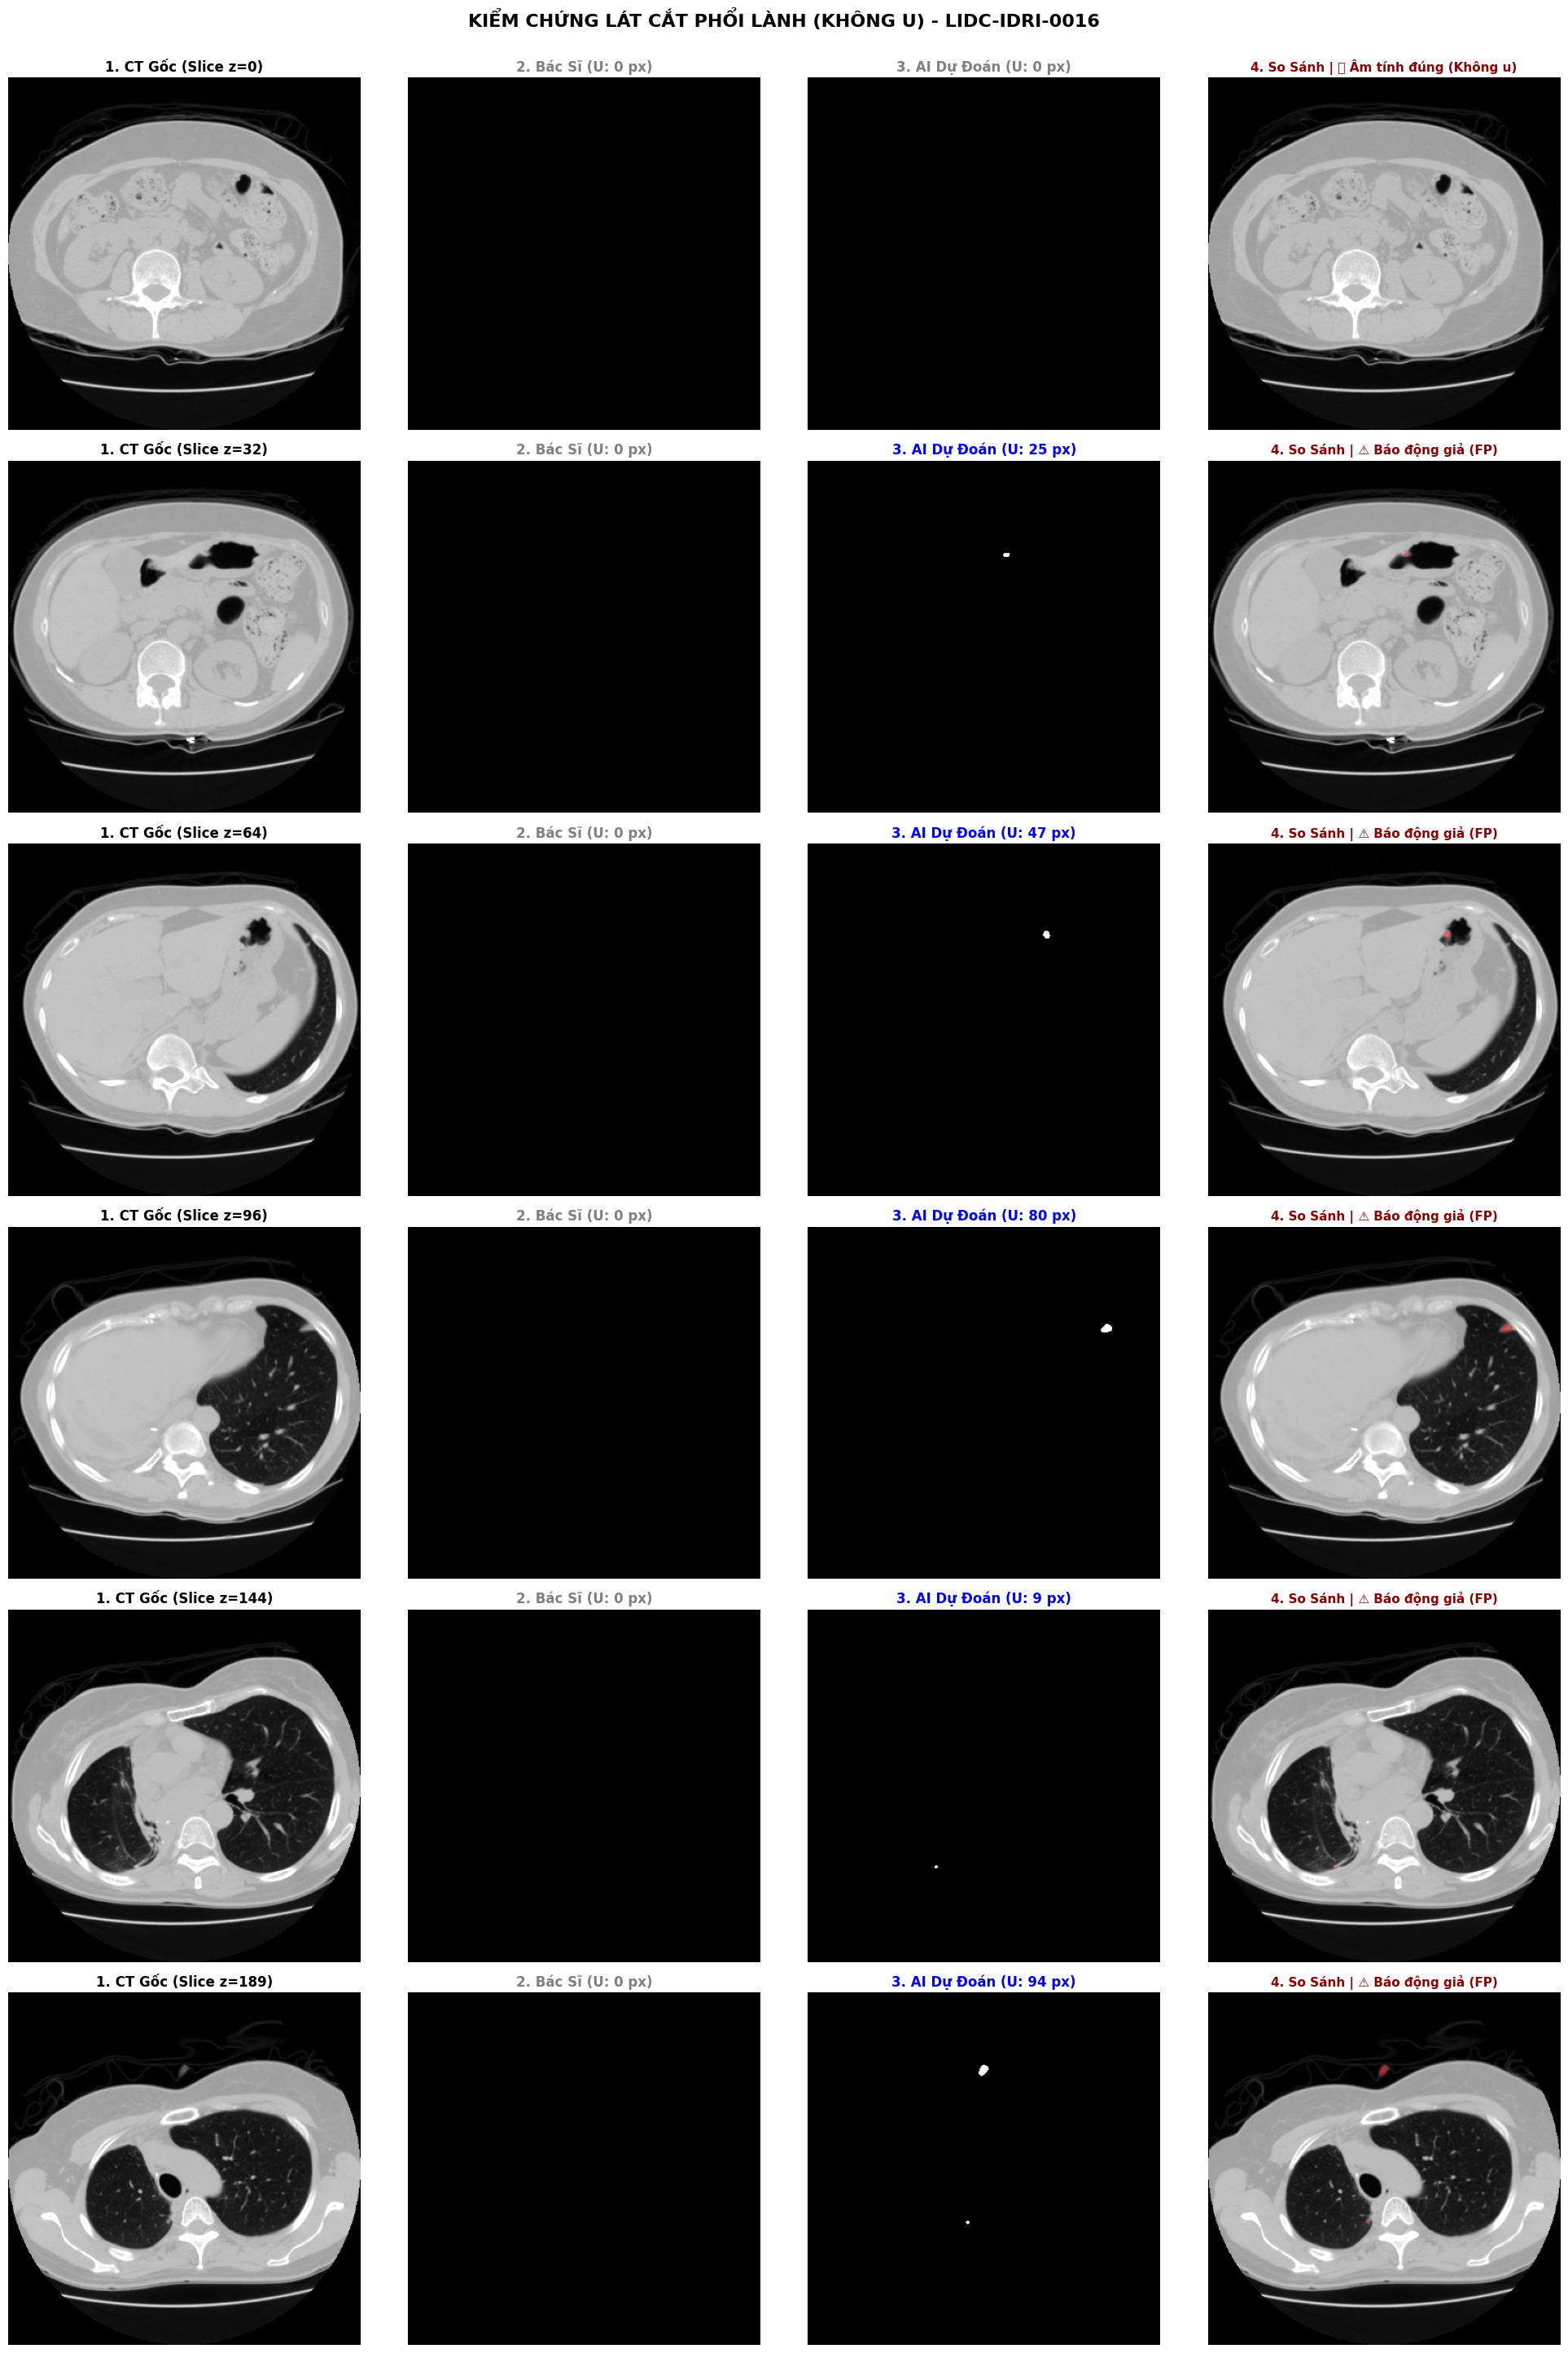

In [ ]:
# Chọn 6 lát cắt phổi hoàn toàn bình thường từ các độ cao khác nhau của lồng ngực
if clean_slice_indices:
    sample_step = max(1, len(clean_slice_indices) // 6)
    test_clean_z = clean_slice_indices[::sample_step][:6]

    print(f'🔍 Đang kiểm tra 6 lát cắt phổi lành ngẫu nhiên (z = {test_clean_z}):')
    display_slice_comparison(test_clean_z, title_prefix='KIỂM CHỨNG LÁT CẮT PHỔI LÀNH (KHÔNG U)')
else:
    print('Không tìm thấy lát cắt lành!')


## 12. Xuất Báo Cáo Định Lượng Ra Bảng CSV
Lưu lại bảng thống kê chi tiết từng lát cắt (Dice, IoU, diện tích thật, diện tích AI, tình trạng) để phục vụ viết đồ án hoặc làm báo cáo.


In [ ]:
import pandas as pd

output_dir = Path('evaluation_results/patient_case_inspections')
output_dir.mkdir(parents=True, exist_ok=True)

df_results = pd.DataFrame(all_metrics)
csv_out_path = output_dir / f'{SELECTED_PATIENT}_slice_by_slice_analysis.csv'
df_results.to_csv(csv_out_path, index=False)

print(f'💾 Đã xuất báo cáo chi tiết từng lát cắt tại:')
print(f'   {csv_out_path.resolve()}')

# Hiển thị các lát cắt quanh vùng nốt u
if nodule_slice_indices:
    focus_df = df_results[(df_results['z'] >= min(nodule_slice_indices) - 2) & (df_results['z'] <= max(nodule_slice_indices) + 2)]
    print('\n📊 BẢNG TRÍCH ĐOẠN XUNG QUANH VÙNG NỐT U:')
    display(focus_df[['z', 'gt_area', 'pred_area', 'dice', 'iou', 'status']])


💾 Đã xuất báo cáo chi tiết từng lát cắt tại:
   /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/unet_baseline/evaluation_results/patient_case_inspections/LIDC-IDRI-0016_slice_by_slice_analysis.csv

📊 BẢNG TRÍCH ĐOẠN XUNG QUANH VÙNG NỐT U:


,z,gt_area,pred_area,dice,iou,status
118,118,0,6,0.000000,0.000000,⚠️ Báo động giả (FP)
119,119,0,16,0.000000,0.000000,⚠️ Báo động giả (FP)
120,120,48,62,0.618182,0.447368,⭐ Trùng khớp (Dice: 0.62)
121,121,48,175,0.421525,0.267045,⭐ Trùng khớp (Dice: 0.42)
122,122,199,247,0.802691,0.670412,⭐ Trùng khớp (Dice: 0.80)
...,...,...,...,...,...,...
219,219,146,46,0.479167,0.315068,⭐ Trùng khớp (Dice: 0.48)
220,220,11,0,0.000000,0.000000,❌ Bỏ sót nốt u (FN)
221,221,11,0,0.000000,0.000000,❌ Bỏ sót nốt u (FN)
222,222,0,0,1.000000,1.000000,✅ Âm tính đúng (Không u)
